# Strategy A against Strategy B on the football graph (context on)

Both strategies on the same 239 context-on tasks (`football-v1-ctx-idmix`), the same 5 models and 3 runs:
**A zero-shot**, **A mean** (the 9 prompts pooled), **A best** (each model's best prompt by F1 on these tasks,
an optimistic upper bound for A), **B search** and **B search + memory**.

**Scoring.** Each task hides one property. The answer of a configuration (model, prompt or approach) is the vote over
its 3 runs (text: most frequent value; numbers: mean; abstained only when all 3 runs abstain), and is **correct**,
**wrong** or **abstained**. **F1** = 2c / (2c + 2w + a) counts abstentions against recall; **F1 (abstentions ignored)**
= 2c / (2c + w) scores only the answers given (the paper's Table 3 scoring). Intervals are 95% bootstrap intervals
over tasks (1,000 resamples); paired differences resample the same tasks for both sides; task-by-task comparisons use
an exact McNemar test on "correct".

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"))
from paper_report_lib import *
FOLDER = "football_ab"

v = load_voted(("football", "ctx"))
runs = load_runs(("football", "ctx"))
eff = load_effort(); eff = eff[(eff.dataset == "football") & (eff.set == "ctx")]
mp = metrics(v[v.strategy == "A"], ["model", "approach"])
BEST = mp.loc[mp.groupby("model").f1.idxmax()].set_index("model").approach.to_dict()
BEST_IGN = mp.loc[mp.groupby("model").f1_ign.idxmax()].set_index("model").approach.to_dict()
def cfg(r):
    if r.strategy == "A":
        return "A best" if r.approach == BEST[r.model] else ("A zero-shot" if r.approach == "zero" else None)
    return "B search" if r.approach == "search_evidence" else "B search + memory"
v["cfg"] = v.apply(cfg, axis=1)
C = ["A zero-shot", "A best", "B search", "B search + memory"]
CC = {"A zero-shot": "#cde2fb", "A best": "#86b6ef", "A mean": "#c9c8c2", "B search": "#eb6834", "B search + memory": "#a8380c"}
pd.DataFrame({"best prompt (F1)": BEST, "best prompt (F1 ign)": BEST_IGN}).rename(index=MNAME)

,best prompt (F1),best prompt (F1 ign)
deepseek-v4.1-flash,few_3,few_5
gemma4:31b,compact,fewcot_3
gpt-oss:120b,compact,few_5
gpt-oss:20b,compact,fewcot_3
mistral-large-3,few_5,few_5


## 1. Headline comparison

### Score per model and approach

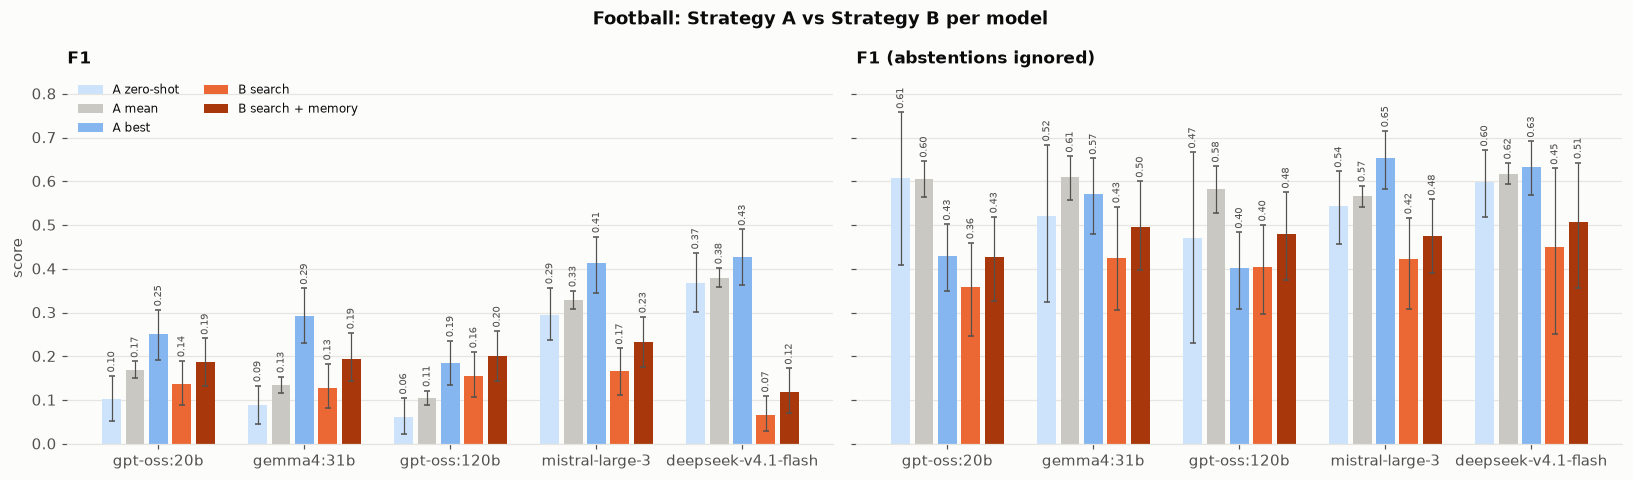

f1                                               f1_ign                                               abstention                                              
cfg                 A best A mean A zero-shot B search B search + memory A best A mean A zero-shot B search B search + memory     A best A mean A zero-shot B search B search + memory
model                                                                                                                                                                                 
deepseek-v4.1-flash  0.428  0.380       0.368    0.067             0.118  0.633  0.618       0.599    0.450             0.507      0.142  0.261       0.247    0.870             0.791
gemma4:31b           0.292  0.135       0.088    0.128             0.195  0.570  0.610       0.522    0.426             0.496      0.423  0.819       0.858    0.690             0.582
gpt-oss:120b         0.185  0.105       0.060    0.156             0.200  0.402  0.582       0.471    0.403             0.479      0.418  0.853       0.891    0.552             0.536
gpt-oss:20b          0.250  0.169       0.103    0.138             0.187  0.430  0.605       0.609    0.358             0.428      0.159  0.759       0.866    0.540             0.477
mistral-large-3      0.413  0.329       0.294    0.167             0.232  0.654  0.566       0.545    0.423             0.476      0.259  0.285       0.351    0.548             0.410

In [2]:
t = pd.concat([boot(v[v.cfg.notna()], ["model", "cfg"]), boot(v[v.strategy == "A"], ["model"]).assign(cfg="A mean")])
order = ["A zero-shot", "A mean", "A best", "B search", "B search + memory"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
for ax, (s, n) in zip(axes, SCORES):
    grouped_bars(ax, t, "model", MODELS, "cfg", order, s, CC, names=MNAME, labels=True); ax.set_title(n)
axes[0].legend(fontsize=8, loc="upper left", ncol=2); axes[0].set_ylabel("score")
fig.suptitle("Football: Strategy A vs Strategy B per model")
save(fig, FOLDER, "ab_bars")
display(t.assign(model=t.model.map(MNAME)).pivot(index="model", columns="cfg", values=["f1", "f1_ign", "abstention"]).round(3))

On football, Strategy A with a good prompt beats Strategy B for four of five models. A best reaches F1 0.19–0.43 and B with memory 0.12–0.23. Only gpt-oss:120b, the most cautious model under Strategy A, scores as high with B + memory (0.20) as with its best prompt (0.19). Zero-shot is the weakest A condition for the cautious models (F1 0.06–0.10), and B beats it. For deepseek and mistral, even zero-shot A (0.37 and 0.29) is far above B. On F1 ign, A best (0.40–0.65) is above B + memory (0.43–0.51) for gemma4, mistral and deepseek, ties for gpt-oss:20b (0.43) and is below it for gpt-oss:120b (0.40 vs 0.48).

### Paired differences B − A (same tasks)

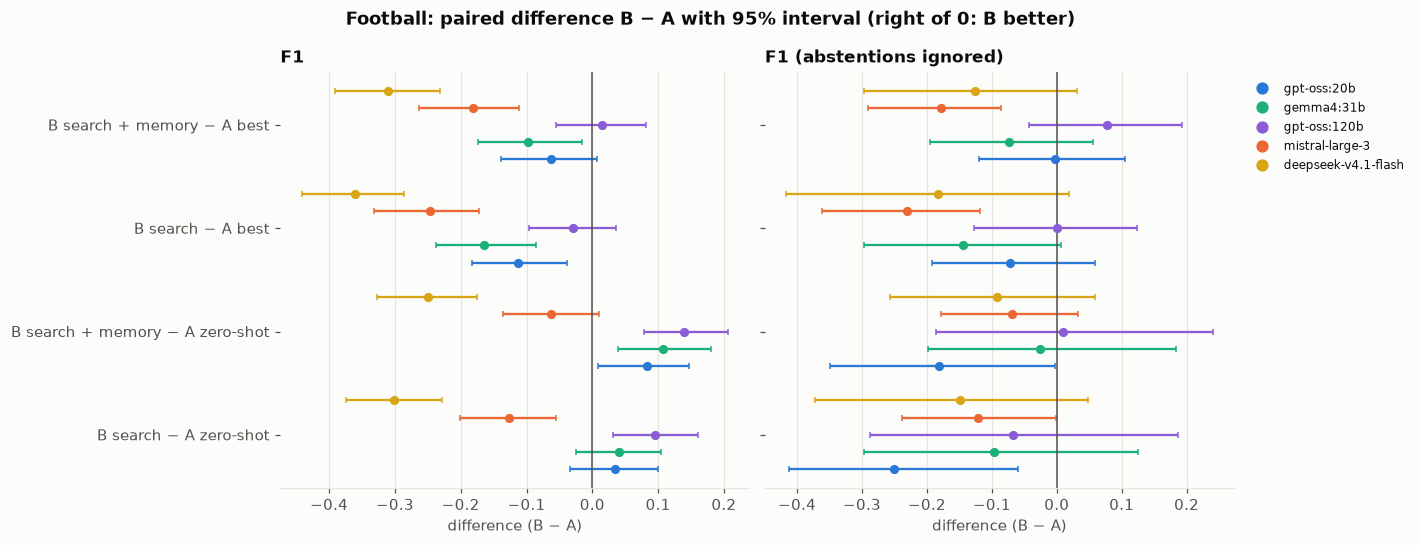

,model,pair,diff,lo,hi,both right,only A right,only B right,neither right,p (McNemar)
0,gpt-oss:20b,B search − A zero-shot,0.034,-0.034,0.099,3,11,21,204,0.110
2,gpt-oss:20b,B search + memory − A zero-shot,0.083,0.009,0.148,5,9,29,196,0.002
4,gpt-oss:20b,B search − A best,-0.112,-0.183,-0.038,8,47,16,168,0.000
6,gpt-oss:20b,B search + memory − A best,-0.063,-0.138,0.007,15,40,19,165,0.009
8,gemma4:31b,B search − A zero-shot,0.040,-0.025,0.104,2,10,18,209,0.185
10,gemma4:31b,B search + memory − A zero-shot,0.107,0.039,0.181,3,9,30,197,0.001
12,gemma4:31b,B search − A best,-0.164,-0.238,-0.086,6,49,14,170,0.000
14,gemma4:31b,B search + memory − A best,-0.097,-0.174,-0.015,12,43,21,163,0.008
16,gpt-oss:120b,B search − A zero-shot,0.096,0.032,0.160,1,7,26,205,0.001
18,gpt-oss:120b,B search + memory − A zero-shot,0.140,0.079,0.206,3,5,32,199,0.000


In [3]:
rows = []
for m in MODELS:
    for a in ("A zero-shot", "A best"):
        for b in ("B search", "B search + memory"):
            x = v[(v.model == m) & (v.cfg == a)].set_index("task_id").outcome
            y = v[(v.model == m) & (v.cfg == b)].set_index("task_id").outcome
            for s, n in SCORES:
                d, lo, hi = paired_diff(x, y, s)
                rows.append({"model": m, "pair": f"{b} − {a}", "score": n, "diff": d, "lo": lo, "hi": hi, **paired(x, y)})
pdf = pd.DataFrame(rows)
pairs = pdf.pair.unique().tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (s, n) in zip(axes, SCORES):
    d = pdf[pdf.score == n]
    for i, p in enumerate(pairs):
        for j, m in enumerate(MODELS):
            r = d[(d.pair == p) & (d.model == m)].iloc[0]
            y = i * 6 + j
            ax.errorbar(r["diff"], y, xerr=[[r["diff"] - r.lo], [r.hi - r["diff"]]], fmt="o", color=MCOLOR[m], ms=5, capsize=2)
    ax.axvline(0, color=INK2, lw=1); ax.set_title(n); ax.set_xlabel("difference (B − A)")
    ax.set_yticks([i * 6 + 2 for i in range(len(pairs))]); ax.set_yticklabels(pairs); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
axes[1].legend(handles=model_handles(), fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Football: paired difference B − A with 95% interval (right of 0: B better)")
save(fig, FOLDER, "ab_forest")
display(pdf[pdf.score == "F1"][["model", "pair", "diff", "lo", "hi", "both right", "only first right", "only second right", "neither right", "p (McNemar)"]]
        .assign(model=lambda x: x.model.map(MNAME)).rename(columns={"only first right": "only A right", "only second right": "only B right"}))

The paired differences confirm this. Against A zero-shot, B + memory is significantly better for gpt-oss:20b (+0.08), gemma4 (+0.11) and gpt-oss:120b (+0.14), and significantly worse for deepseek (−0.25); for mistral the interval includes 0 (−0.06). Against A best, B + memory is significantly worse for gemma4 (−0.10), mistral (−0.18) and deepseek (−0.31), and not different for gpt-oss:20b and gpt-oss:120b. With abstentions ignored most intervals include 0; the clear exceptions are mistral, whose answers are less accurate with B + memory than with A best (−0.18), and gpt-oss:20b, whose answers are less accurate with B search than with A zero-shot (−0.25).

### Task-by-task: who gets each task right

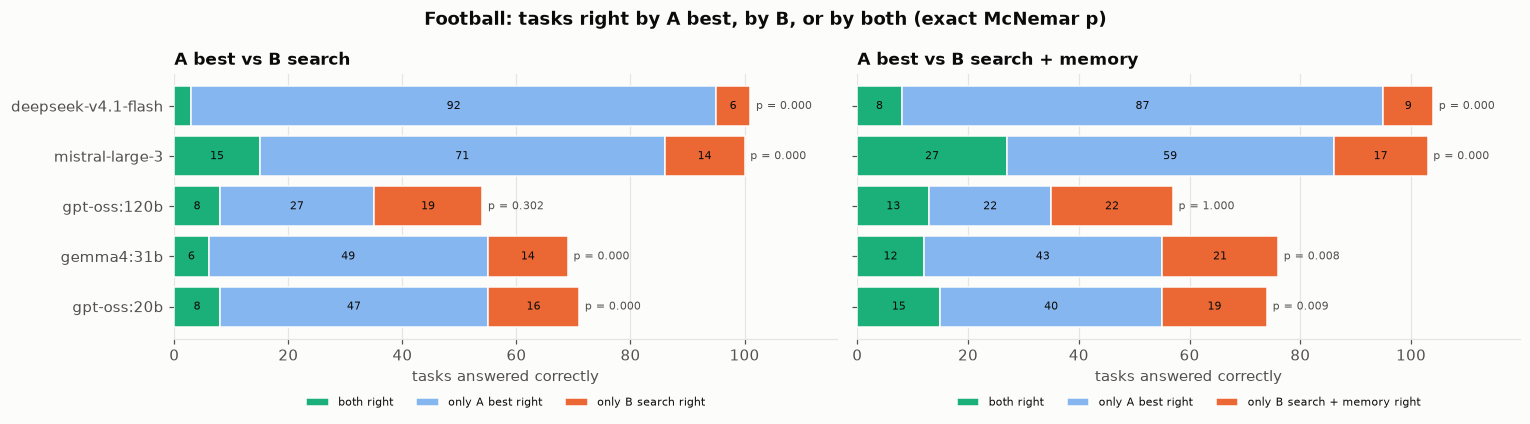

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, b in zip(axes, ("B search", "B search + memory")):
    rows = []
    for m in MODELS:
        x = v[(v.model == m) & (v.cfg == "A best")].set_index("task_id").outcome
        y = v[(v.model == m) & (v.cfg == b)].set_index("task_id").outcome
        rows.append({"model": m, **paired(x, y)})
    t = pd.DataFrame(rows).set_index("model").reindex(MODELS)
    parts = [("both right", AQUA), ("only first right", "#86b6ef"), ("only second right", ORANGE)]
    left = np.zeros(len(t))
    for c, col in parts:
        ax.barh(range(len(t)), t[c], left=left, color=col, label=c.replace("first", "A best").replace("second", b), edgecolor=SURFACE)
        for yy, l_, w_ in zip(range(len(t)), left, t[c]):
            if w_ >= 4: ax.text(l_ + w_ / 2, yy, int(w_), ha="center", va="center", fontsize=7.5)
        left += t[c].to_numpy()
    for yy, p_ in enumerate(t["p (McNemar)"]):
        ax.text(left[yy] + 1, yy, f"p = {p_:.3f}", va="center", fontsize=7.5, color=INK2)
    ax.set_yticks(range(len(t))); ax.set_yticklabels(MN); ax.invert_yaxis(); ax.set_title(f"A best vs {b}")
    ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3); ax.set_xlim(0, left.max() * 1.15)
    ax.set_xlabel("tasks answered correctly"); ax.grid(axis="y", visible=False)
fig.suptitle("Football: tasks right by A best, by B, or by both (exact McNemar p)")
save(fig, FOLDER, "ab_taskwise")

Counting tasks, A best and B get different tasks right. For gpt-oss:120b, 22 tasks are right only with A best and 22 only with B + memory (p = 1.0). For the other models, A best wins clearly (40–87 tasks only A, 9–21 only B, all p ≤ 0.009). The overlap is small: 8–27 tasks are right under both, so the two strategies are partly complementary.

### Precision against recall, all approaches

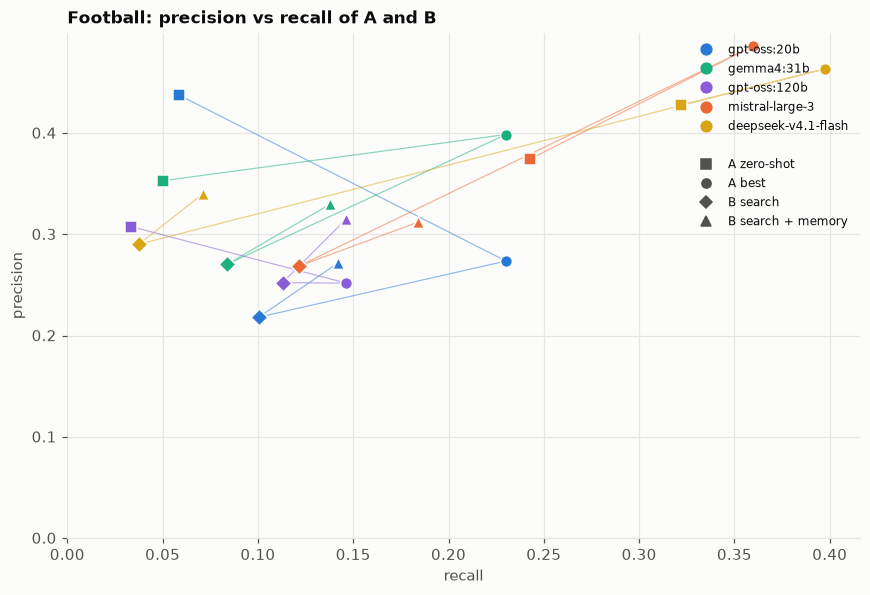

In [5]:
t = metrics(v[v.cfg.notna()], ["model", "cfg"])
MK = {"A zero-shot": "s", "A best": "o", "B search": "D", "B search + memory": "^"}
fig, ax = plt.subplots(figsize=(8, 5.5))
for _, r in t.iterrows():
    ax.scatter(r.recall, r.precision, marker=MK[r.cfg], s=60, color=MCOLOR[r.model], edgecolor=SURFACE, zorder=3)
for m in MODELS:
    d = t[t.model == m].set_index("cfg").reindex(C)
    ax.plot(d.recall, d.precision, color=MCOLOR[m], lw=0.8, alpha=0.5)
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, None); ax.set_ylim(0, None)
h = model_handles() + [plt.Line2D([], [], ls="", marker="", label="")] + [plt.Line2D([], [], ls="", marker=mk, color=INK2, label=c) for c, mk in MK.items()]
ax.legend(handles=h, fontsize=8, loc="upper right")
ax.set_title("Football: precision vs recall of A and B")
save(fig, FOLDER, "ab_precision_recall")

In precision–recall space, A best lies to the right of B for every model except gpt-oss:120b: A answers far more tasks at similar or higher precision. B's precision on football (0.22–0.34) is below that of A zero-shot and A best for deepseek and mistral (0.37–0.49).

## 2. Where each strategy works

### Score per stratum

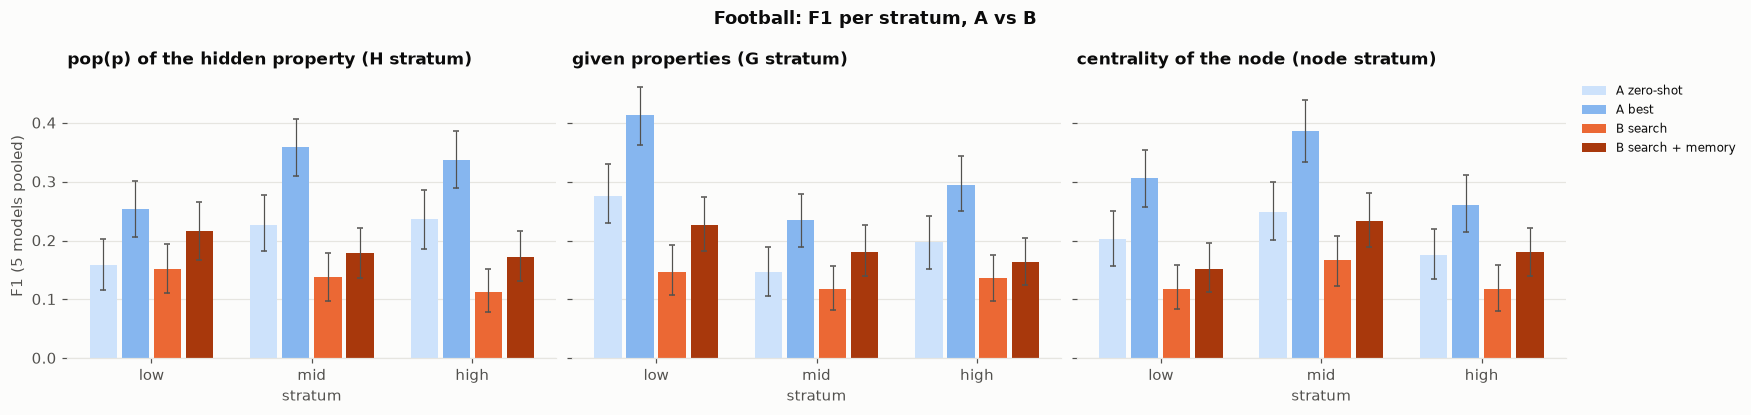

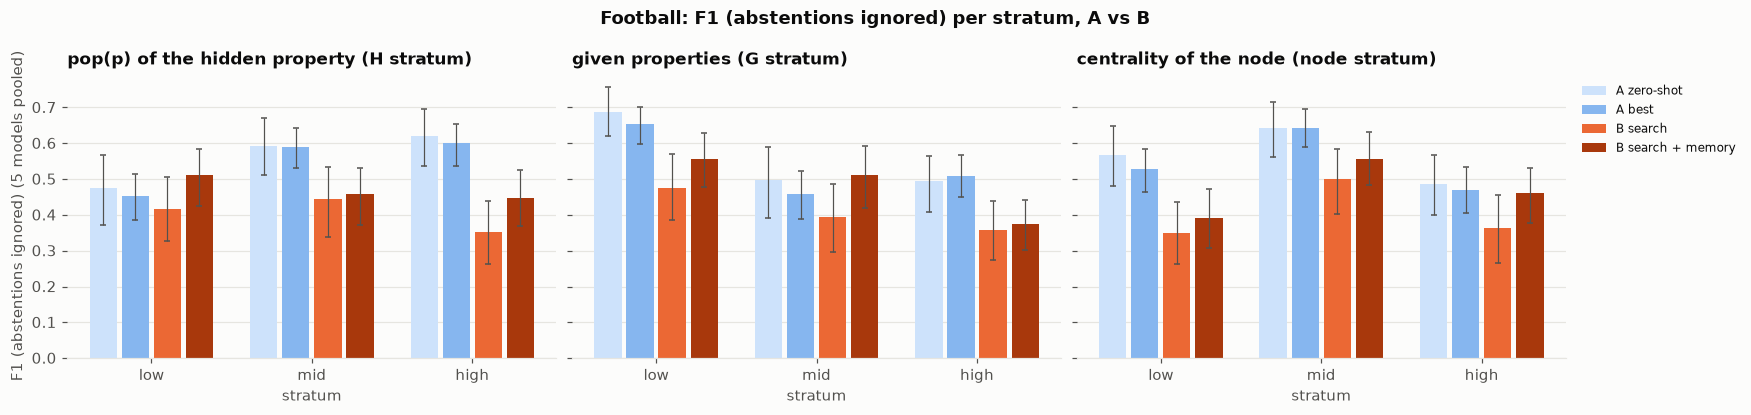

In [6]:
for s, n in SCORES:
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
    for ax, (f, fn) in zip(axes, FACTORS.items()):
        t = boot(v[v.cfg.notna()], ["cfg", f])
        grouped_bars(ax, t, f, STRATA, "cfg", C, s, CC, labels=False); ax.set_title(fn); ax.set_xlabel("stratum")
    axes[0].set_ylabel(f"{n} (5 models pooled)"); axes[-1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.suptitle(f"Football: {n} per stratum, A vs B")
    save(fig, FOLDER, f"ab_strata_{s}")

Pooled over models, A best is ahead of B + memory in every stratum, with the largest gaps where A is strongest: low-G tasks (F1 0.41 vs 0.23) and mid-centrality nodes (0.39 vs 0.23). B is flat across strata (0.15–0.23). B gains nothing where the hidden property is common (high H: A best 0.34, B + memory 0.17), unlike on airports, where search helps most for popular properties.

### Name and team in the given properties (high-G tasks)

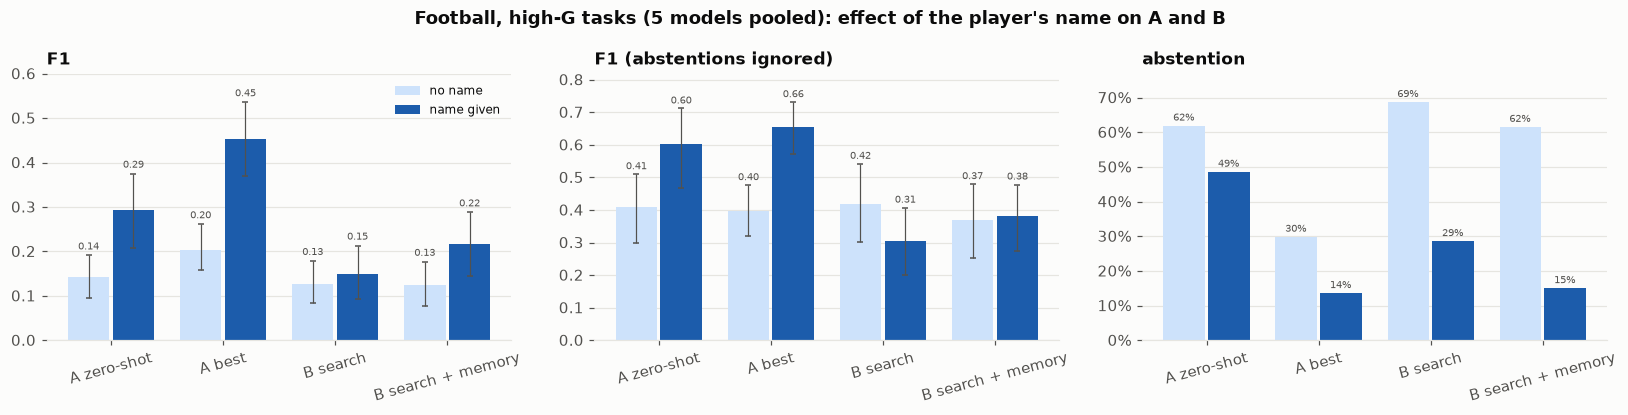

In [7]:
d = v[v.cfg.notna() & (v.G_stratum == "high")].copy()
d["name given"] = np.where(d.has_name, "name given", "no name")
t = boot(d, ["cfg", "name given"])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (s, n) in zip(axes, SCORES + [("abstention", "abstention")]):
    grouped_bars(ax, t, "cfg", C, "name given", ["no name", "name given"], s, {"no name": "#cde2fb", "name given": "#1c5cab"}, err=s != "abstention")
    ax.set_title(n); ax.set_xticklabels(C, rotation=15)
axes[0].legend(fontsize=8); pct(axes[2])
fig.suptitle("Football, high-G tasks (5 models pooled): effect of the player's name on A and B")
save(fig, FOLDER, "ab_identifiers")

The name helps A much more than B. In the high-G tasks, A best goes from F1 0.20 to 0.45 and F1 ign 0.40 to 0.66 when the name is given; B + memory goes only from 0.13 to 0.22 and its F1 ign stays at 0.37–0.38. With the name, the model often recognises the player from its training data. B also finds the player's page, but then reads the wrong value from it.

### Score against difficulty

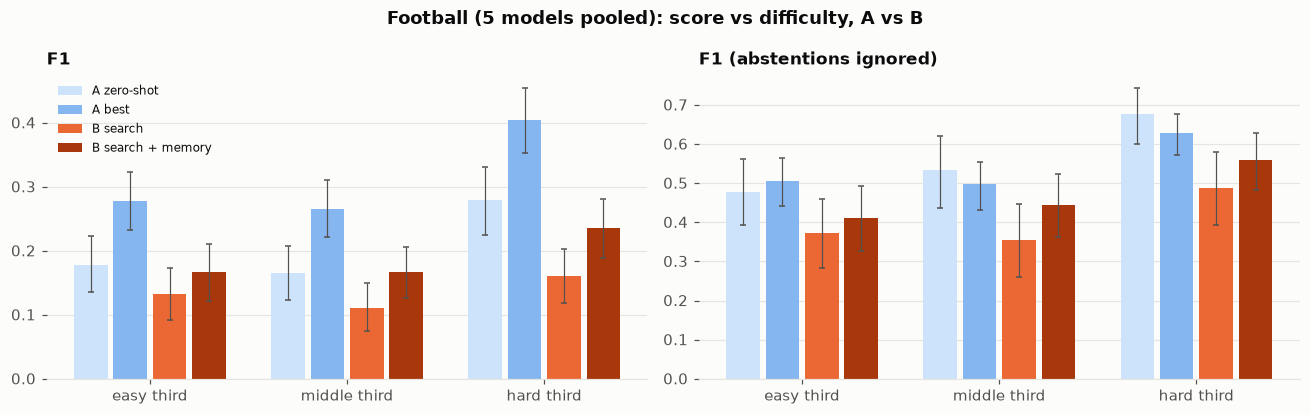

In [8]:
d = v[v.cfg.notna()].copy(); d["bin"] = pd.qcut(d.difficulty, 3, labels=["easy third", "middle third", "hard third"])
t = boot(d, ["cfg", "bin"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (s, n) in zip(axes, SCORES):
    grouped_bars(ax, t, "bin", ["easy third", "middle third", "hard third"], "cfg", C, s, CC, labels=False); ax.set_title(n)
axes[0].legend(fontsize=8)
fig.suptitle("Football (5 models pooled): score vs difficulty, A vs B")
save(fig, FOLDER, "ab_difficulty")

Both strategies score highest on the hardest tertile (A best 0.40, B + memory 0.24) and the gap between them is similar in every tertile (0.10–0.17 F1). The difficulty score does not separate the tasks where retrieval helps from those where it does not.

### Score per hidden property and approach

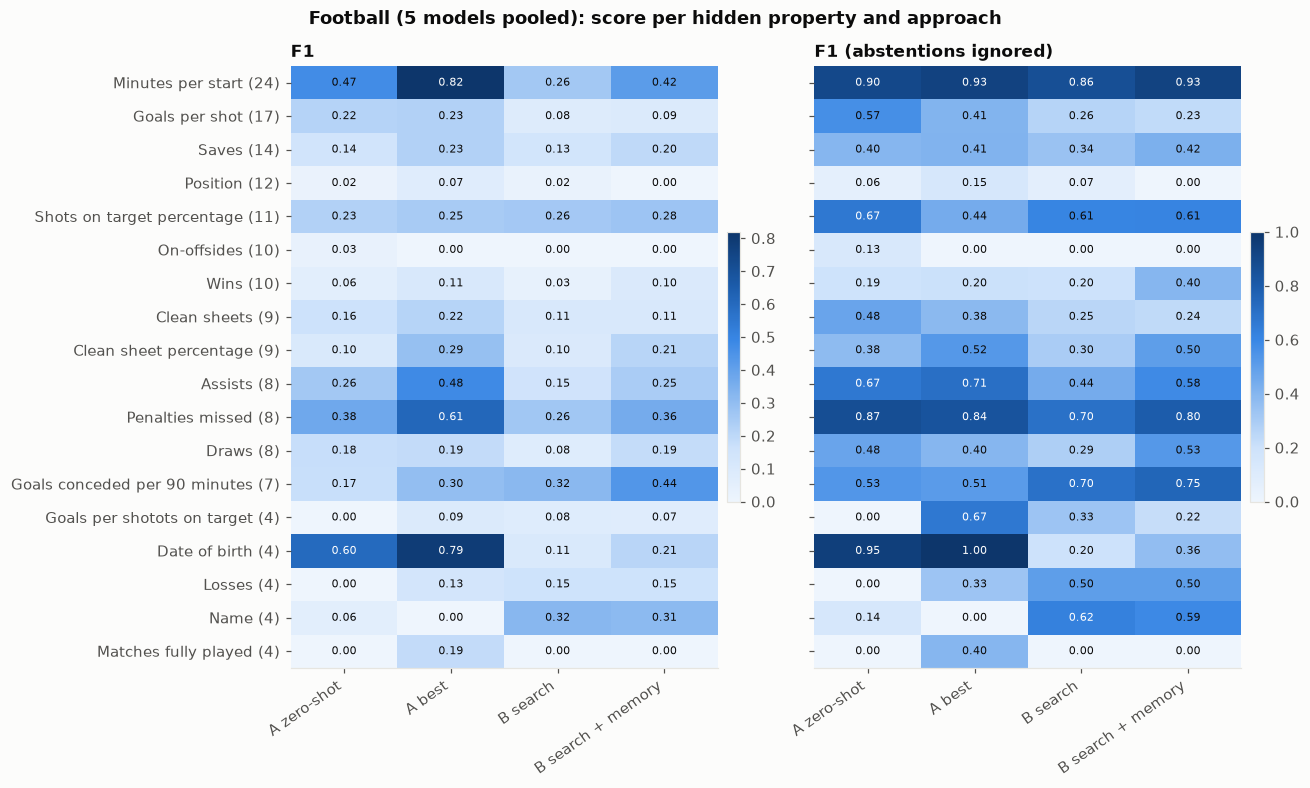

In [9]:
t = metrics(v[v.cfg.notna()], ["property", "cfg"])
ntask = v.drop_duplicates("task_id").property.value_counts(); props = ntask[ntask >= 4].index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 0.32 * len(props) + 1.5))
for ax, (s, n) in zip(axes, SCORES):
    pv = t[t.property.isin(props)].pivot(index="property", columns="cfg", values=s).reindex(index=props, columns=C)
    heat(ax, pv, xlabels=C, ylabels=[f"{p} ({ntask[p]})" for p in props] if s == "f1" else [""] * len(props)); ax.set_title(n)
fig.suptitle("Football (5 models pooled): score per hidden property and approach")
save(fig, FOLDER, "ab_properties")

Per property, B helps where a value is published in a standard place: *Goals conceded per 90 minutes* (F1 0.44 with B + memory vs 0.30 for A best) and *Name* (0.31 vs 0.00). It also gives a better F1 ign for *Losses* (0.50 vs 0.33) and *Wins* with memory (0.40 vs 0.20). A best is far ahead on values the model can estimate: *Minutes per start* (0.82 vs 0.42), *Date of birth* (0.79 vs 0.21), *Penalties missed* (0.61 vs 0.36) and *Assists* (0.48 vs 0.25). *Position* and *On-offsides* are almost never right under any approach.

### Complementarity: an oracle that takes whichever is right

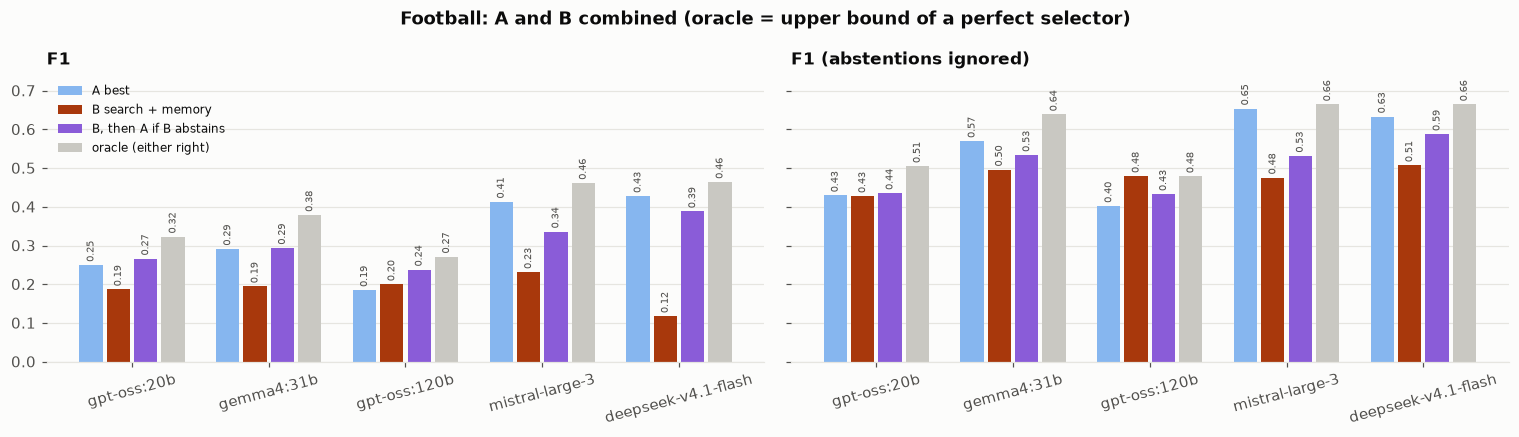

In [10]:
rows = []
for m in MODELS:
    a = v[(v.model == m) & (v.cfg == "A best")].set_index("task_id").outcome
    b = v[(v.model == m) & (v.cfg == "B search + memory")].set_index("task_id").outcome
    j = pd.concat([a.rename("a"), b.rename("b")], axis=1)
    orc = np.where((j.a == "correct") | (j.b == "correct"), "correct", np.where((j.a == "wrong") | (j.b == "wrong"), "wrong", "abstained"))
    # B first, A when B abstains: a deployable combination
    fb = np.where(j.b != "abstained", j.b, j.a)
    for name, o in (("A best", j.a), ("B search + memory", j.b), ("B, then A if B abstains", pd.Series(fb)), ("oracle (either right)", pd.Series(orc))):
        s = metrics(pd.DataFrame({"outcome": o, "k": 0}), ["k"]).iloc[0]
        rows.append({"model": m, "cfg": name, "f1": s.f1, "f1_ign": s.f1_ign, "recall": s.recall})
t = pd.DataFrame(rows)
O = ["A best", "B search + memory", "B, then A if B abstains", "oracle (either right)"]
OC = dict(zip(O, ["#86b6ef", "#a8380c", VIOLET, NEUTRAL]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (s, n) in zip(axes, SCORES):
    grouped_bars(ax, t, "model", MODELS, "cfg", O, s, OC, names=MNAME, err=False); ax.set_title(n); ax.set_xticklabels(MN, rotation=15)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Football: A and B combined (oracle = upper bound of a perfect selector)")
save(fig, FOLDER, "ab_complementarity")

Because A best and B get different tasks right, combining them helps. A deployable rule, *use B and fall back on A when B abstains*, beats A best for gpt-oss:20b (F1 0.27 vs 0.25) and gpt-oss:120b (0.24 vs 0.19), ties for gemma4 (0.29) and loses for mistral (0.34 vs 0.41) and deepseek (0.39 vs 0.43), whose B answers are worse than their A answers. An oracle that picks whichever is right would reach 0.27–0.46. That bounds what a confidence-based selector could gain: 0.03–0.09 over A best.

### When both answer, do they give the same value?

,model,both answered,same answer,precision when same,precision when different (A),precision when different (B)
0,gpt-oss:20b,107,0.168,0.222,0.270,0.292
1,gemma4:31b,76,0.145,0.273,0.400,0.369
2,gpt-oss:120b,69,0.188,0.385,0.268,0.286
3,mistral-large-3,111,0.099,0.636,0.480,0.330
4,deepseek-v4.1-flash,46,0.087,0.500,0.548,0.310


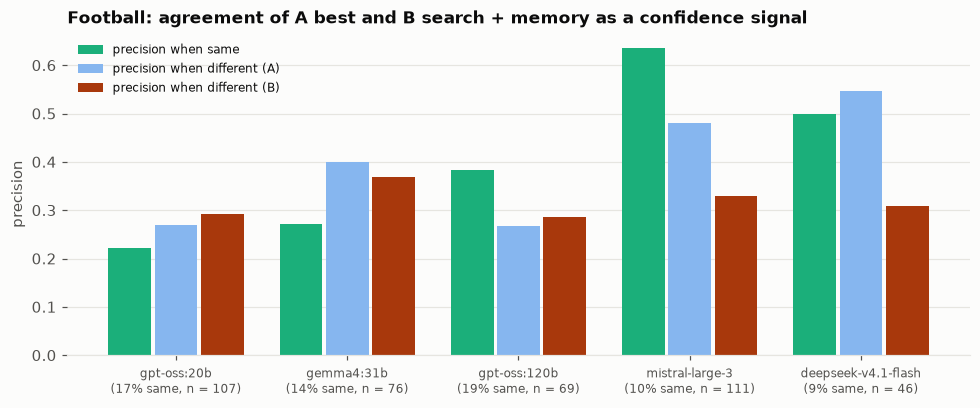

In [11]:
rows = []
for m in MODELS:
    a = v[(v.model == m) & (v.cfg == "A best")].set_index("task_id")
    b = v[(v.model == m) & (v.cfg == "B search + memory")].set_index("task_id")
    j = a[["answer", "outcome"]].join(b[["answer", "outcome"]], lsuffix="_a", rsuffix="_b")
    j = j[(j.outcome_a != "abstained") & (j.outcome_b != "abstained")]
    same = j.answer_a.astype(str).str.lower() == j.answer_b.astype(str).str.lower()
    rows.append({"model": MNAME[m], "both answered": len(j), "same answer": same.mean(),
                 "precision when same": (j[same].outcome_a == "correct").mean(), "precision when different (A)": (j[~same].outcome_a == "correct").mean(),
                 "precision when different (B)": (j[~same].outcome_b == "correct").mean()})
t = pd.DataFrame(rows); display(t)
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(t))
for i, (c, col) in enumerate([("precision when same", AQUA), ("precision when different (A)", "#86b6ef"), ("precision when different (B)", "#a8380c")]):
    ax.bar(x + (i - 1) * 0.27, t[c], 0.25, color=col, label=c)
ax.set_xticks(x); ax.set_xticklabels([f"{m}\n({s:.0%} same, n = {n})" for m, s, n in zip(t.model, t["same answer"], t["both answered"])], fontsize=8)
ax.legend(fontsize=8); ax.grid(axis="x", visible=False); ax.set_ylabel("precision")
ax.set_title("Football: agreement of A best and B search + memory as a confidence signal")
save(fig, FOLDER, "ab_agreement")

When both strategies answer, they agree on the value in only 9–19% of the tasks. Agreement is a useful confidence signal only for the strong models: for mistral, an answer both strategies give is right 64% of the time, against 48% (A) and 33% (B) when they differ. For the smaller models the agreed answers are no more reliable than the others, because they share the same wrong default values.

## 3. Cost of the gain

### Score against energy and token amplification

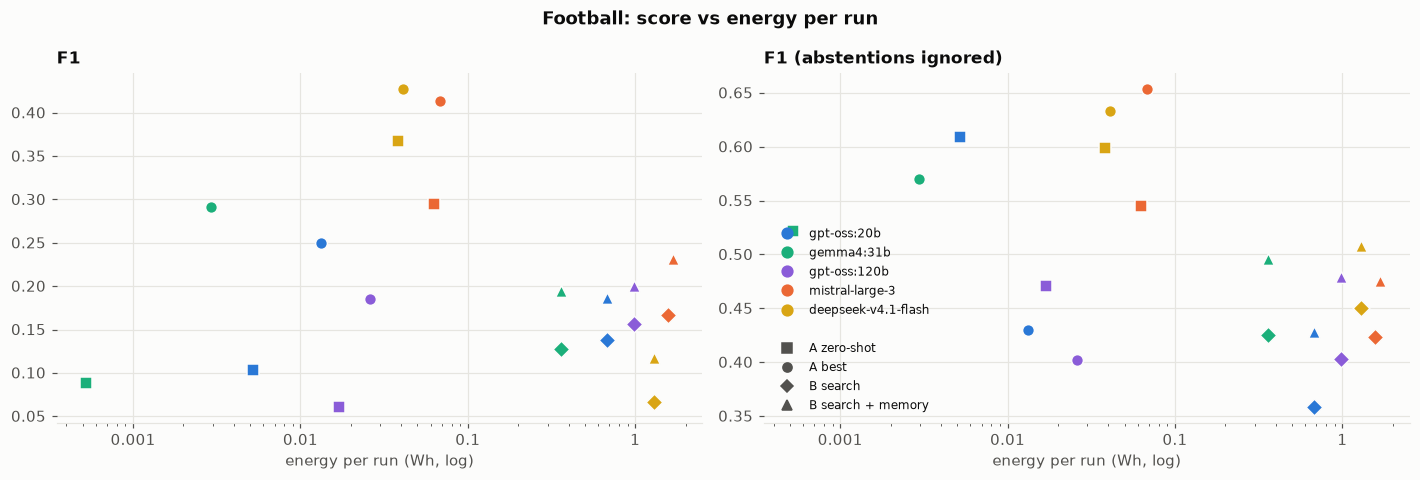

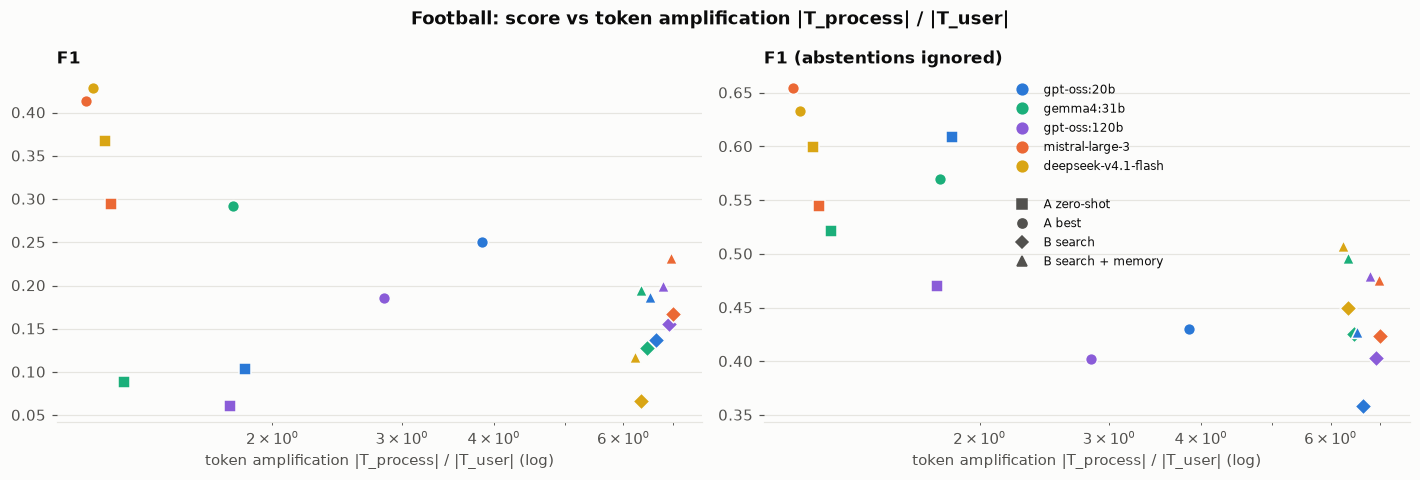

EC                                           amp                                        latency                                       
cfg                 A best A zero-shot B search B search + memory A best A zero-shot B search B search + memory  A best A zero-shot B search B search + memory
model                                                                                                                                                         
deepseek-v4.1-flash  0.041       0.038    1.297             1.298  1.141       1.185    6.338             6.229   0.631       0.607    5.254             5.178
gemma4:31b           0.003       0.001    0.359             0.359  1.766       1.258    6.453             6.341   0.822       0.546    3.005             3.066
gpt-oss:120b         0.026       0.017    0.988             0.986  2.834       1.750    6.921             6.779   1.021       0.818    6.427             6.263
gpt-oss:20b          0.013       0.005    0.681             0.681  3.856       1.834    6.636             6.518   2.704       1.362    6.937             6.865
mistral-large-3      0.069       0.063    1.577             1.686  1.116       1.208    7.008             6.972   1.345       1.613    8.366             8.777

In [12]:
eff["cfg"] = None
for m in MODELS:
    eff.loc[(eff.model == m) & (eff.strategy == "A") & (eff.approach == BEST[m]), "cfg"] = "A best"
eff.loc[(eff.strategy == "A") & (eff.approach == "zero") & eff.cfg.isna(), "cfg"] = "A zero-shot"
eff.loc[eff.approach == "search_evidence", "cfg"] = "B search"; eff.loc[eff.approach == "search_memory", "cfg"] = "B search + memory"
e = eff[eff.cfg.notna()].groupby(["model", "cfg"]).agg(EC=("EC_run", "mean"), proc=("tokens_proc", "sum"), user=("tokens_user", "sum"),
                                                       latency=("latency_s", "mean")).reset_index()
e["amp"] = e.proc / e.user
t = metrics(v[v.cfg.notna()], ["model", "cfg"]).merge(e, on=["model", "cfg"])
MK = {"A zero-shot": "s", "A best": "o", "B search": "D", "B search + memory": "^"}
for xc, xn, fn in (("EC", "energy per run (Wh, log)", "ab_energy"), ("amp", "token amplification |T_process| / |T_user| (log)", "ab_amplification")):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    for ax, (s, n) in zip(axes, SCORES):
        for _, r in t.iterrows():
            ax.scatter(r[xc], r[s], marker=MK[r.cfg], s=60, color=MCOLOR[r.model], edgecolor=SURFACE, zorder=3)
        logaxis(ax, "x"); ax.set_xlabel(xn); ax.set_title(n)
    h = model_handles() + [plt.Line2D([], [], ls="", marker="", label="")] + [plt.Line2D([], [], ls="", marker=mk, color=INK2, label=c) for c, mk in MK.items()]
    axes[1].legend(handles=h, fontsize=8, loc="best")
    fig.suptitle(f"Football: score vs {xn.split(' (')[0]}")
    save(fig, FOLDER, fn)
display(e.assign(model=e.model.map(MNAME)).pivot(index="model", columns="cfg", values=["EC", "amp", "latency"]).round(4))

B costs much more than A for a lower F1 on football. A run of B takes 0.36–1.69 Wh, 23–120× the energy of the same model's best A prompt (0.003–0.069 Wh). Its token amplification is 6.2–7.0×, against 1.1–3.9× for A. Every model's A points dominate its B points (higher or equal F1 at lower energy) except gpt-oss:120b, where B + memory gains 0.015 F1 for 38× the energy.

### Run agreement, A vs B

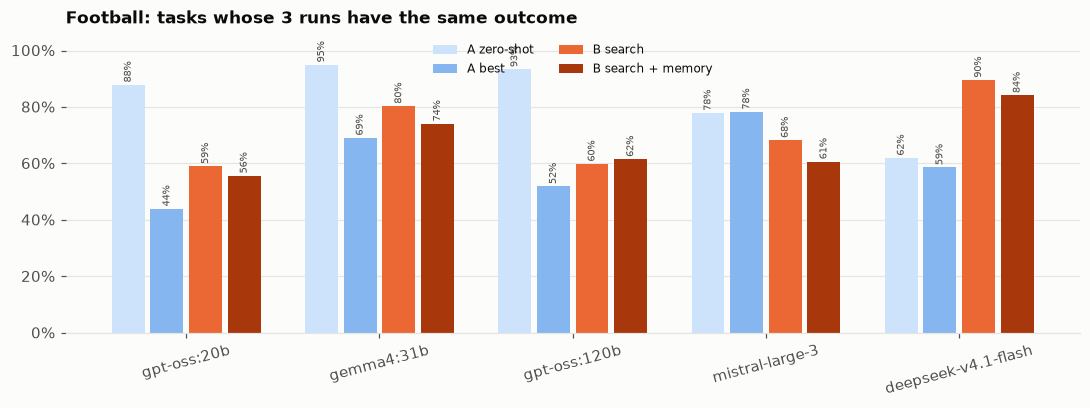

In [13]:
r = runs.copy()
r["cfg"] = r.apply(cfg, axis=1)
ag = agreement(r[r.cfg.notna()], ["model", "cfg"])
fig, ax = plt.subplots(figsize=(10, 3.8))
grouped_bars(ax, ag, "model", MODELS, "cfg", C, "same outcome in all runs", CC, names=MNAME, err=False, fmt="{:.0%}")
pct(ax); ax.set_xticklabels(MN, rotation=15); ax.legend(fontsize=8, ncol=2)
ax.set_title("Football: tasks whose 3 runs have the same outcome")
save(fig, FOLDER, "ab_stability")

The three runs of A best agree on the outcome for 60% of the tasks on average and those of A zero-shot for 83%. B is in between (search 71%, memory 67%). The A best prompt is often compact, which is the least stable prompt. Stability does not differ enough to change the comparison.

## Takeaways

1. **On football, A with a good prompt beats B** for four of five models (A best F1 0.19–0.43 vs B + memory 0.12–0.23); only gpt-oss:120b ties (0.19 vs 0.20).
2. **B beats zero-shot A only for the cautious models** (gpt-oss:20b, gemma4, gpt-oss:120b: +0.08 to +0.14 F1), and mainly because it abstains less than they do under zero-shot.
3. **The two strategies are complementary**: few tasks are right under both, and *B, then A if B abstains* improves on A best for the two gpt-oss models; an oracle would add 0.03–0.09 F1.
4. **The player's name helps A (+0.25 F1) much more than B (+0.09)**: memory recognises the player; search finds the page but reads the wrong value.
5. **B is 23–120× more expensive** in energy than the model's best A prompt and amplifies the user's input 6–7×, for a lower F1 on this dataset.